# MLDR explorer

[MLDR](https://huggingface.co/datasets/Shitao/MLDR) (Multilingual Long-Document Retrieval, released with BGE-M3,
arXiv:2402.03216) is a retrieval benchmark over **long documents** from Wikipedia, Wudao and mC4 in 13 languages
(ar, de, en, es, fr, hi, it, ja, ko, pt, ru, th, zh). Each query is a question that GPT-3.5 generated from one
paragraph of one document.

Each language directory `mldr-v1.0-<lang>/` on the Hub has four gzipped JSONL files:

| file | one line is |
|---|---|
| `train/dev/test.jsonl.gz` | `{query_id, query, positive_passages: [{docid, text}], negative_passages: [{docid, text}, ...]}` |
| `corpus.jsonl.gz` | `{docid, text}`: the full retrieval corpus (about 1 GB compressed for English) |

`dev` is MLDR's validation split.

The files are loaded with the Hugging Face `datasets` library. The Hub repo also ships a loading script
(`MLDR.py`), but `datasets` 4 and later no longer run loading scripts, so the notebook reads the JSONL files with
the generic `json` builder and `hf://` paths.

The notebook first gives an overview of every language: queries per split, documents, and document length in
characters. It then looks at one language in detail (queries per document, an example), counts how many
480-token chunks and how much of the 4096-byte clawmarc card text area each document needs, and can export a
sample of documents as `.txt` files for `reference/libangel_catalog.py`.

The `datasets` cache lives under `data/mldr/hf_cache/` at the repo root, which is git-ignored.

In [ ]:
# Requirements: datasets, pandas, matplotlib; transformers (tokenizer only, no torch) for the chunk counts.
# %pip install datasets pandas matplotlib transformers

## Configuration

In [2]:
from pathlib import Path

LANGS = ["ar", "de", "en", "es", "fr", "hi", "it", "ja", "ko", "pt", "ru", "th", "zh"]
MAIN_LANG = "en"                 # language for the detailed sections
SPLITS = ["dev", "test"]         # splits loaded for every language in LANGS
LOAD_TRAIN = False               # train is about 6 GB compressed over all 13 languages (en 1.3 GB, zh 1.9 GB);
                                 # False takes the train query counts from the dataset card instead
CORPUS_LANGS = []                # languages whose full corpus is loaded for document counts and lengths,
                                 # e.g. ["hi", "ko"]; the rest take corpus counts from the dataset card

TOKENIZER = "bert-base-multilingual-cased"  # clawmarc profile 2; None skips the chunk counts
CHUNK_TOKENS = 480               # chunk size used by the clawmarc producer and run_ir_experiments.py
CARD_TEXT_BYTES = 1280           # card text area when a 768-dim profile-2 vector fills the rest of the arena

RUN_CORPUS = False               # read MAIN_LANG's corpus.jsonl.gz (about 1 GB compressed for en)
CORPUS_MAX_DOCS = 20_000         # stream only this many corpus docs; None loads the whole corpus

EXPORT_N = 0                     # write this many positive docs of MAIN_LANG as .txt for libangel_catalog.py

REPO = Path.cwd() if (Path.cwd() / "reference").is_dir() else Path.cwd().parent
DATA_DIR = REPO / "data" / "mldr"
CACHE_DIR = DATA_DIR / "hf_cache"

## Loading helpers

In [4]:
import textwrap

import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import Features, Value, load_dataset
from matplotlib.ticker import FuncFormatter, PercentFormatter

datasets.logging.set_verbosity_error()
datasets.disable_progress_bars()   # one bar per split and map is too noisy over 13 languages

HUB = "hf://datasets/Shitao/MLDR"
NO_SPACES = {"zh", "ja", "th"}   # whitespace word counts are meaningless for these
ALL_SPLITS = ["train", "dev", "test"]

PASSAGES = [{"docid": Value("string"), "text": Value("string")}]
QUERY_FEATURES = Features({"query_id": Value("string"), "query": Value("string"),
                           "positive_passages": PASSAGES, "negative_passages": PASSAGES})
CORPUS_FEATURES = Features({"docid": Value("string"), "text": Value("string")})

# Published counts from the dataset card (README.md on the Hub), used where the data isn't loaded.
CARD = pd.DataFrame(
    [("ar", 1817, 200, 200, 7607), ("de", 1847, 200, 200, 10000), ("en", 10000, 200, 800, 200000),
     ("es", 2254, 200, 200, 9551), ("fr", 1608, 200, 200, 10000), ("hi", 1618, 200, 200, 3806),
     ("it", 2151, 200, 200, 10000), ("ja", 2262, 200, 200, 10000), ("ko", 2198, 200, 200, 6176),
     ("pt", 1845, 200, 200, 6569), ("ru", 1864, 200, 200, 10000), ("th", 1970, 200, 200, 10000),
     ("zh", 10000, 200, 800, 200000)],
    columns=["lang", "train", "dev", "test", "corpus"],
).set_index("lang")


def hub_file(lang: str, name: str) -> str:
    return f"{HUB}/mldr-v1.0-{lang}/{name}.jsonl.gz"


def load_queries(lang: str, split: str) -> datasets.Dataset:
    """One query split as a memory-mapped Dataset; downloaded once, then read from CACHE_DIR."""
    return load_dataset("json", data_files={split: hub_file(lang, split)}, split=split,
                        features=QUERY_FEATURES, cache_dir=str(CACHE_DIR))


def load_corpus(lang: str, streaming: bool = False):
    return load_dataset("json", data_files={"corpus": hub_file(lang, "corpus")}, split="corpus",
                        features=CORPUS_FEATURES, cache_dir=str(CACHE_DIR), streaming=streaming)


def _query_stats(batch):
    pos, neg = batch["positive_passages"], batch["negative_passages"]
    docs = [p[0]["text"] if p else "" for p in pos]
    return {
        "query_id": batch["query_id"],
        "query": batch["query"],
        "n_pos": [len(p) for p in pos],
        "n_neg": [len(n) for n in neg],
        "pos_docid": [p[0]["docid"] if p else None for p in pos],
        "neg_docids": [[x["docid"] for x in n] for n in neg],
        "query_chars": [len(x) for x in batch["query"]],
        "doc_chars": [len(d) for d in docs],
        "doc_bytes": [len(d.encode("utf-8")) for d in docs],
        "doc_words": [len(d.split()) for d in docs],
    }


def load_split(lang: str, split: str):
    """Per-query statistics as a DataFrame, plus the Dataset itself for looking at the text."""
    ds = load_queries(lang, split)
    # small batches: train rows carry the full text of every negative document
    stats = ds.map(_query_stats, batched=True, batch_size=100, remove_columns=ds.column_names)
    df = stats.to_pandas()
    df.insert(0, "lang", lang)
    df.insert(1, "split", split)
    if lang in NO_SPACES:
        df["doc_words"] = np.nan
    return df, ds


def corpus_lengths(lang: str) -> pd.DataFrame:
    ds = load_corpus(lang)
    lens = ds.map(lambda b: {"docid": b["docid"],
                             "chars": [len(t) for t in b["text"]],
                             "bytes": [len(t.encode("utf-8")) for t in b["text"]]},
                  batched=True, remove_columns=ds.column_names)
    df = lens.to_pandas()
    df.insert(0, "lang", lang)
    return df

### Chart style

In [5]:
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
SPLIT_COLORS = {"train": "#2a78d6", "dev": "#eb6834", "test": "#1baf7a"}   # fixed order: blue, orange, aqua
SPLIT_LABELS = {"train": "train", "dev": "dev (validation)", "test": "test"}
ONE_SERIES = "#2a78d6"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#a6a59f", "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK, "legend.frameon": False,
})
thousands = FuncFormatter(lambda v, _: f"{v:,.0f}")
kilo = FuncFormatter(lambda v, _: f"{v / 1000:g}k")
LOG_TICKS = [1_000, 2_000, 5_000, 10_000, 20_000, 50_000, 100_000, 200_000, 500_000]


def log_char_axis(ax, fmt=thousands):
    """Readable ticks for a log-scaled character axis."""
    lo, hi = ax.get_xlim()
    ax.set_xticks([t for t in LOG_TICKS if lo <= t <= hi])
    ax.xaxis.set_major_formatter(fmt)
    ax.xaxis.set_minor_formatter(plt.NullFormatter())


def bar_labels(ax, values, ys, fmt="{:,.0f}"):
    """Value at the end of each horizontal bar, in secondary ink."""
    for y, v in zip(ys, values):
        ax.text(v, y, " " + fmt.format(v), va="center", ha="left", fontsize=8, color=INK_2)

## Overview of all languages

`SPLITS` of every language in `LANGS` are loaded (about 400 MB for dev and test of all 13 languages). Columns that
come from the dataset card rather than from the loaded data are marked as such.

In [6]:
load_splits = SPLITS + (["train"] if LOAD_TRAIN and "train" not in SPLITS else [])
frames, DS = [], {}
for lang in LANGS:
    print(f"loading {lang} {load_splits} ...", flush=True)
    for split in load_splits:
        df, DS[lang, split] = load_split(lang, split)
        frames.append(df)
qall = pd.concat(frames, ignore_index=True)

corpus_frames = []
for lang in CORPUS_LANGS:
    print(f"loading {lang} corpus ...", flush=True)
    corpus_frames.append(corpus_lengths(lang))
corpus_all = pd.concat(corpus_frames, ignore_index=True) if corpus_frames else None

print(f"{len(qall):,} queries loaded from {len(LANGS)} languages, splits {load_splits}")
if corpus_all is not None:
    print(f"{len(corpus_all):,} corpus documents loaded from {CORPUS_LANGS}")

loading ar ['dev', 'test'] ...


loading de ['dev', 'test'] ...
loading en ['dev', 'test'] ...
loading es ['dev', 'test'] ...
loading fr ['dev', 'test'] ...
loading hi ['dev', 'test'] ...
loading it ['dev', 'test'] ...
loading ja ['dev', 'test'] ...
loading ko ['dev', 'test'] ...
loading pt ['dev', 'test'] ...
loading ru ['dev', 'test'] ...
loading th ['dev', 'test'] ...
loading zh ['dev', 'test'] ...
6,400 queries loaded from 13 languages, splits ['dev', 'test']


### Queries per language and split

Query counts per split. Splits that were not loaded fall back to the dataset card; the cell checks that the
loaded counts agree with the card.

In [7]:
loaded = qall.pivot_table(index="lang", columns="split", values="query_id", aggfunc="size")
counts = CARD.loc[LANGS, ALL_SPLITS].copy()
from_card = [s for s in ALL_SPLITS if s not in loaded.columns]
for s in loaded.columns:
    counts[s] = loaded[s]
mismatch = (counts != CARD.loc[LANGS, ALL_SPLITS]).any(axis=1)
if mismatch.any():
    print("loaded counts differ from the dataset card for:", list(mismatch[mismatch].index))
if from_card:
    print("from the dataset card (not loaded):", from_card)

table = counts.copy()
table["total"] = counts.sum(axis=1)
for s in ALL_SPLITS:
    table[f"{s} %"] = (100 * counts[s] / table["total"]).round(1)
table.loc["all"] = table.sum(numeric_only=True)
for s in ALL_SPLITS:
    table.loc["all", f"{s} %"] = round(100 * table.loc["all", s] / table.loc["all", "total"], 1)
table

from the dataset card (not loaded): ['train']


,train,dev,test,total,train %,dev %,test %
lang,,,,,,,
ar,1817.0,200.0,200.0,2217.0,82.0,9.0,9.0
de,1847.0,200.0,200.0,2247.0,82.2,8.9,8.9
en,10000.0,200.0,800.0,11000.0,90.9,1.8,7.3
es,2254.0,200.0,200.0,2654.0,84.9,7.5,7.5
fr,1608.0,200.0,200.0,2008.0,80.1,10.0,10.0
hi,1618.0,200.0,200.0,2018.0,80.2,9.9,9.9
it,2151.0,200.0,200.0,2551.0,84.3,7.8,7.8
ja,2262.0,200.0,200.0,2662.0,85.0,7.5,7.5
ko,2198.0,200.0,200.0,2598.0,84.6,7.7,7.7


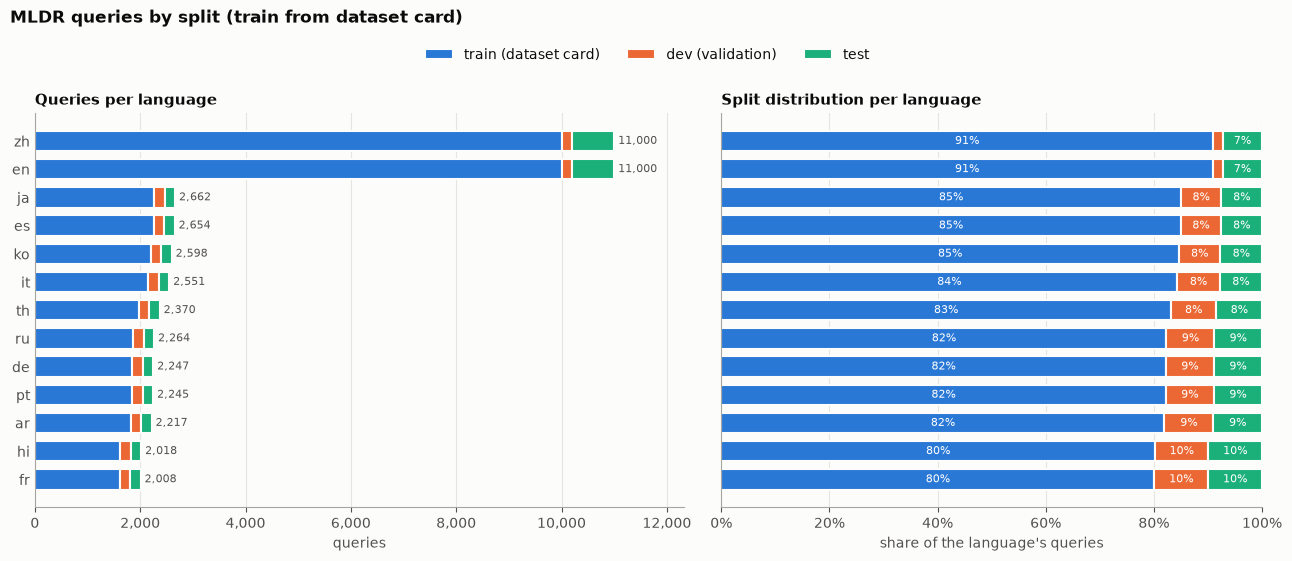

In [8]:
order = counts.sum(axis=1).sort_values().index       # largest language at the top
ys = np.arange(len(order))
card_note = f" ({', '.join(from_card)} from dataset card)" if from_card else ""

fig, (ax_n, ax_s) = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True, gridspec_kw={"width_ratios": [1.2, 1]})
left_n, left_s = np.zeros(len(order)), np.zeros(len(order))
share = counts.loc[order].div(counts.loc[order].sum(axis=1), axis=0)
for s in ALL_SPLITS:
    kw = dict(height=0.72, color=SPLIT_COLORS[s], edgecolor=SURFACE, linewidth=1.5)
    label = SPLIT_LABELS[s] + (" (dataset card)" if s in from_card else "")
    ax_n.barh(ys, counts.loc[order, s], left=left_n, label=label, **kw)
    ax_s.barh(ys, share[s], left=left_s, **kw)
    for y, (l, w) in enumerate(zip(left_s, share[s])):
        if w >= 0.07:   # label only segments wide enough to hold the text
            ax_s.text(l + w / 2, y, f"{w:.0%}", ha="center", va="center", fontsize=8, color="white")
    left_n += counts.loc[order, s].to_numpy()
    left_s += share[s].to_numpy()
bar_labels(ax_n, left_n, ys)

ax_n.set(yticks=ys, yticklabels=order, xlabel="queries", title="Queries per language")
ax_n.xaxis.set_major_formatter(thousands)
ax_n.set_xlim(0, left_n.max() * 1.12)
ax_s.set(xlim=(0, 1), xlabel="share of the language's queries", title="Split distribution per language")
ax_s.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
for ax in (ax_n, ax_s):
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
fig.legend(*ax_n.get_legend_handles_labels(), loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02))
fig.suptitle(f"MLDR queries by split{card_note}", x=0.01, ha="left", y=1.07, fontsize=12, fontweight="bold")
plt.tight_layout()

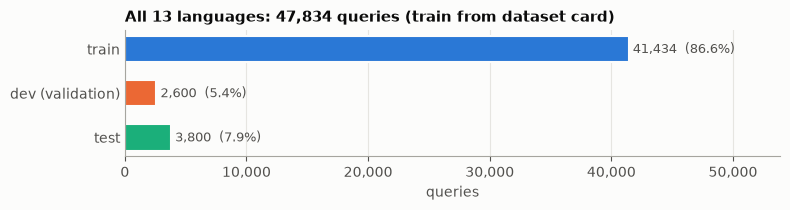

In [9]:
totals = counts.sum()
fig, ax = plt.subplots(figsize=(8, 2.2))
ys = np.arange(len(ALL_SPLITS))[::-1]
ax.barh(ys, totals[ALL_SPLITS], height=0.6, color=[SPLIT_COLORS[s] for s in ALL_SPLITS],
        edgecolor=SURFACE, linewidth=1.5)
for y, s in zip(ys, ALL_SPLITS):
    ax.text(totals[s], y, f" {totals[s]:,}  ({totals[s] / totals.sum():.1%})", va="center", fontsize=9, color=INK_2)
ax.set(yticks=ys, yticklabels=[SPLIT_LABELS[s] for s in ALL_SPLITS], xlabel="queries",
       title=f"All {len(LANGS)} languages: {totals.sum():,} queries{card_note}")
ax.set_xlim(0, totals.max() * 1.3)
ax.xaxis.set_major_formatter(thousands)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()

### Documents per language

The **corpus** is the set of documents a system retrieves from. Its size comes from the loaded corpus for
languages in `CORPUS_LANGS` and from the dataset card for the rest. The second panel counts the distinct
documents that are the positive of at least one loaded query.

,corpus_docs,corpus_source,positive_docs,queries_loaded
lang,,,,
ar,7607,card,400,400
de,10000,card,400,400
en,200000,card,1000,1000
es,9551,card,400,400
fr,10000,card,400,400
hi,3806,card,400,400
it,10000,card,400,400
ja,10000,card,400,400
ko,6176,card,400,400


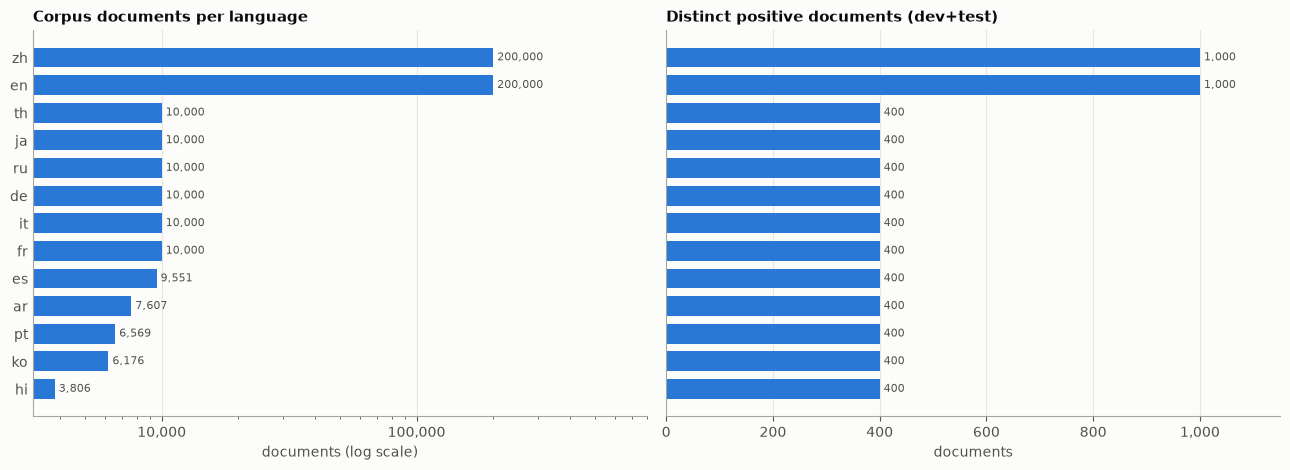

In [10]:
docs = pd.DataFrame({
    "corpus_docs": CARD.loc[LANGS, "corpus"],
    "corpus_source": "card",
    "positive_docs": qall.groupby("lang")["pos_docid"].nunique().reindex(LANGS),
    "queries_loaded": qall.groupby("lang").size().reindex(LANGS),
})
if corpus_all is not None:
    n = corpus_all.groupby("lang").size()
    docs.loc[n.index, "corpus_docs"] = n
    docs.loc[n.index, "corpus_source"] = "loaded"
display(docs)

order = docs["corpus_docs"].sort_values().index
ys = np.arange(len(order))
fig, (ax_c, ax_p) = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
ax_c.barh(ys, docs.loc[order, "corpus_docs"], height=0.72, color=ONE_SERIES)
bar_labels(ax_c, docs.loc[order, "corpus_docs"], ys)
ax_c.set(xscale="log", xlabel="documents (log scale)", title="Corpus documents per language")
ax_c.set_xlim(right=docs["corpus_docs"].max() * 4)
ax_c.xaxis.set_major_formatter(thousands)
ax_p.barh(ys, docs.loc[order, "positive_docs"], height=0.72, color=ONE_SERIES)
bar_labels(ax_p, docs.loc[order, "positive_docs"], ys)
ax_p.set(xlabel="documents", title=f"Distinct positive documents ({'+'.join(load_splits)})")
ax_p.set_xlim(0, docs["positive_docs"].max() * 1.15)
ax_p.xaxis.set_major_formatter(thousands)
ax_c.set(yticks=ys, yticklabels=order)
for ax in (ax_c, ax_p):
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
plt.tight_layout()

### Document length in characters

Each distinct positive document is counted once. For languages in `CORPUS_LANGS` the corpus documents are shown
as well. Characters are Unicode code points, so a Chinese or Japanese character counts as one character but takes
three UTF-8 bytes; `bytes` is what counts against the card's text area.

In [11]:
pos_docs = qall.drop_duplicates(["lang", "pos_docid"])[["lang", "pos_docid", "doc_chars", "doc_bytes"]]
pos_docs = pos_docs.rename(columns={"pos_docid": "docid", "doc_chars": "chars", "doc_bytes": "bytes"})
pos_docs["set"] = "positive"
doc_len = pos_docs
if corpus_all is not None:
    doc_len = pd.concat([pos_docs, corpus_all.assign(set="corpus")], ignore_index=True)


def p(q):
    f = lambda s: s.quantile(q)
    f.__name__ = f"p{int(q * 100)}"
    return f


length_table = doc_len.groupby(["lang", "set"])["chars"].agg(
    ["size", "mean", p(.1), "median", p(.9), "max", "sum"]).round(0).astype(int)
length_table = length_table.rename(columns={"size": "docs", "sum": "total_chars"})
length_table["median_bytes"] = doc_len.groupby(["lang", "set"])["bytes"].median().astype(int)
length_table

,,docs,mean,p10,median,p90,max,total_chars,median_bytes
lang,set,,,,,,,,
ar,positive,400,22353,19244,22274,25726,29587,8941024,39689
de,positive,400,26581,20115,27084,31975,36612,10632235,27495
en,positive,1000,35157,24655,29366,53188,275098,35157129,29436
es,positive,400,28351,25285,27928,32071,36275,11340447,28621
fr,positive,400,25683,22724,25578,28837,34225,10273397,26466
hi,positive,400,21122,17183,20797,25738,31903,8448901,52147
it,positive,400,27745,24096,27484,31788,38089,11097958,27710
ja,positive,400,10789,9468,10716,12274,13791,4315467,30476
ko,positive,400,12150,10591,12044,13948,19196,4860173,27345


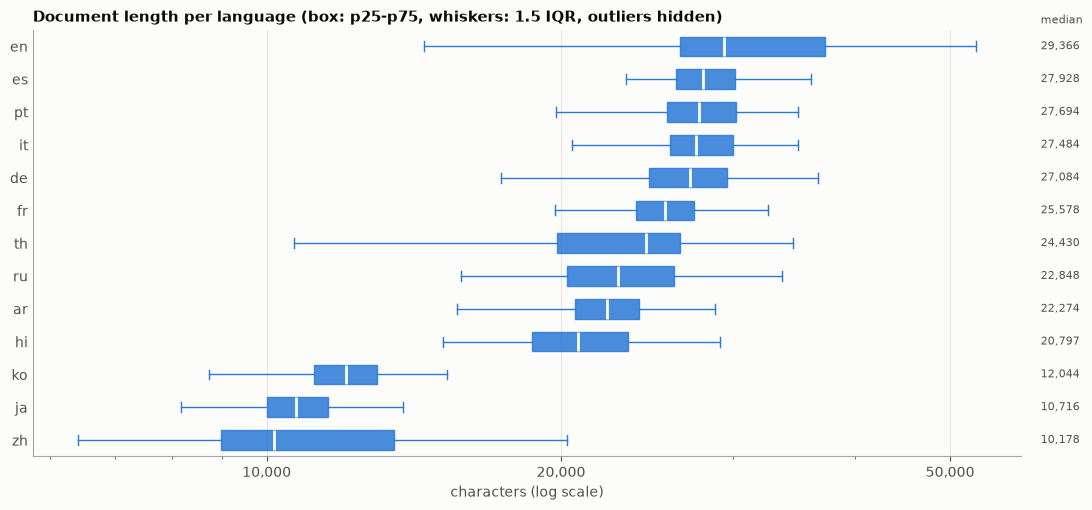

In [12]:
order = pos_docs.groupby("lang")["chars"].median().sort_values().index
ys = np.arange(len(order))
fig, ax = plt.subplots(figsize=(11, 5.2))
groups = [("positive", 0.0, ONE_SERIES)]
if corpus_all is not None:
    groups = [("positive", -0.18, ONE_SERIES), ("corpus", 0.18, "#eb6834")]
for name, dy, color in groups:
    sub = doc_len[doc_len["set"] == name]
    langs = [l for l in order if (sub["lang"] == l).any()]
    pos = [ys[list(order).index(l)] + dy for l in langs]
    ax.boxplot([sub.loc[sub["lang"] == l, "chars"] for l in langs], positions=pos,
               orientation="horizontal", widths=0.3 if len(groups) > 1 else 0.6, showfliers=False,
               patch_artist=True, label=f"{name} docs",
               boxprops=dict(facecolor=color, edgecolor=color, alpha=0.85),
               medianprops=dict(color=SURFACE, linewidth=2), whiskerprops=dict(color=color),
               capprops=dict(color=color))
med = pos_docs.groupby("lang")["chars"].median()
for y, l in zip(ys, order):
    ax.text(1.02, y, f"{med[l]:,.0f}", transform=ax.get_yaxis_transform(), va="center", fontsize=8, color=INK_2)
ax.text(1.02, len(order) - 0.3, "median", transform=ax.get_yaxis_transform(), fontsize=8, color=INK_2)
ax.set(yticks=ys, yticklabels=order, xscale="log", xlabel="characters (log scale)",
       title="Document length per language (box: p25-p75, whiskers: 1.5 IQR, outliers hidden)")
log_char_axis(ax)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
if len(groups) > 1:
    ax.legend(loc="lower right")
plt.tight_layout()

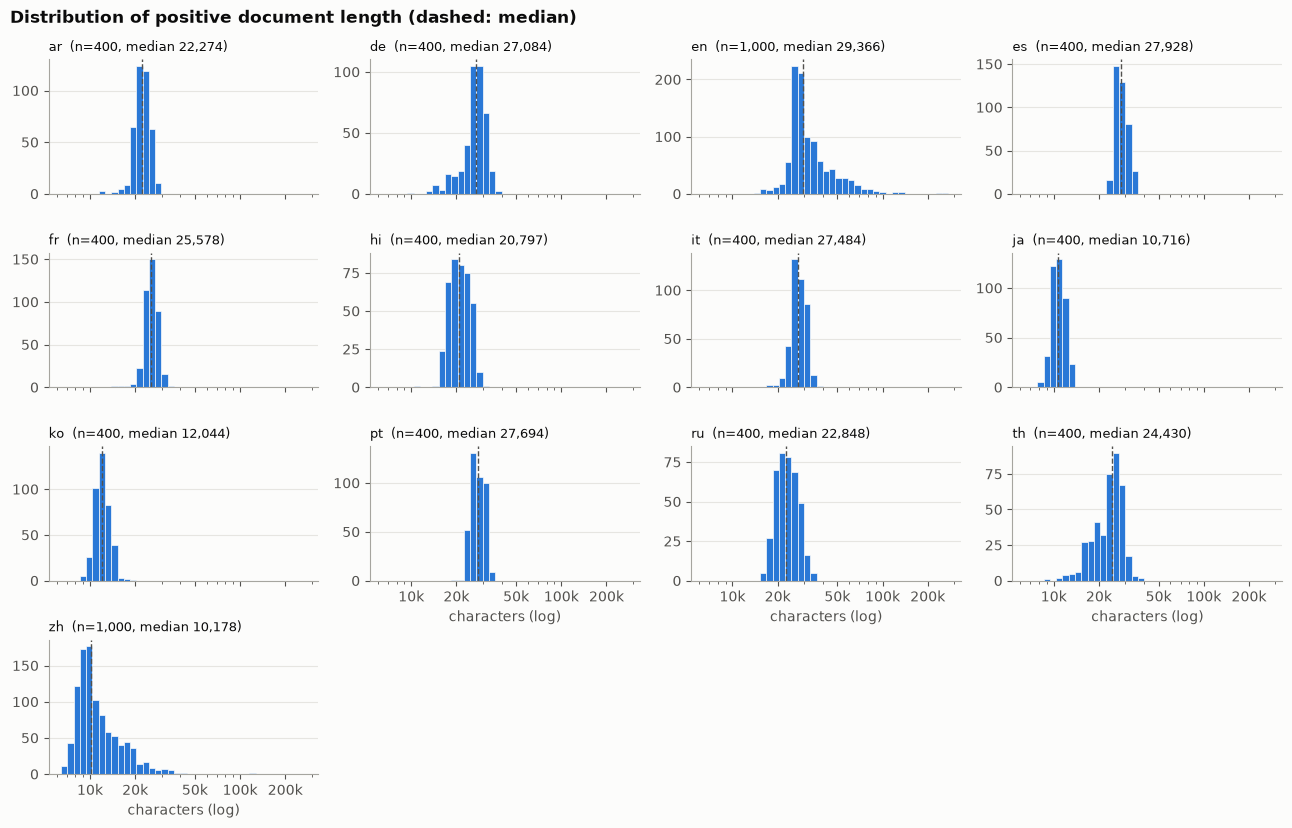

In [13]:
# One small histogram per language, shared log x-axis so the shapes compare directly.
ncols = 4
nrows = -(-len(LANGS) // ncols)
bins = np.logspace(np.log10(max(1, pos_docs["chars"].min())), np.log10(pos_docs["chars"].max()), 40)
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 2.1 * nrows), sharex=True)
for ax, lang in zip(axes.flat, LANGS):
    c = pos_docs.loc[pos_docs["lang"] == lang, "chars"]
    ax.hist(c, bins=bins, color=ONE_SERIES, edgecolor=SURFACE, linewidth=0.5)
    ax.axvline(c.median(), color=INK_2, linewidth=1, linestyle="--")
    ax.set_xscale("log")
    ax.set_title(f"{lang}  (n={len(c):,}, median {c.median():,.0f})", fontsize=9, fontweight="normal")
    ax.grid(axis="x", visible=False)
for ax in axes.flat[len(LANGS):]:
    ax.set_visible(False)
for ax in axes.flat[len(LANGS) - ncols:len(LANGS)]:   # bottom visible plot of each column
    ax.set_xlabel("characters (log)")
    ax.xaxis.set_tick_params(labelbottom=True)
    log_char_axis(ax, kilo)
fig.suptitle("Distribution of positive document length (dashed: median)", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
plt.tight_layout()

### Overview table

Per language: positives and negatives per query, how many queries share one positive document, and document size.
Word counts are left empty for zh, ja and th, which don't separate words with spaces.

In [14]:
overview = qall.groupby("lang").agg(
    queries=("query_id", "size"),
    pos_per_query=("n_pos", "mean"),
    neg_per_query=("n_neg", "mean"),
    max_queries_per_doc=("pos_docid", lambda s: s.value_counts().max()),
    median_query_chars=("query_chars", "median"),
    median_doc_chars=("doc_chars", "median"),
    p90_doc_chars=("doc_chars", lambda s: s.quantile(.9)),
    median_doc_bytes=("doc_bytes", "median"),
    median_doc_words=("doc_words", "median"),
).round(1)
overview

,queries,pos_per_query,neg_per_query,max_queries_per_doc,median_query_chars,median_doc_chars,p90_doc_chars,median_doc_bytes,median_doc_words
lang,,,,,,,,,
ar,400,1.0,7.0,1,67.0,22274.0,25725.5,39689.0,3708.5
de,400,1.0,7.0,1,84.0,27084.0,31975.4,27495.0,3835.5
en,1000,1.0,7.0,1,80.0,29366.5,53187.7,29436.0,4685.5
es,400,1.0,7.0,1,120.0,27927.5,32071.0,28621.5,4607.0
fr,400,1.0,7.0,1,120.0,25578.5,28837.1,26466.0,4071.5
hi,400,1.0,7.0,1,73.0,20797.0,25738.3,52147.0,3779.0
it,400,1.0,7.0,1,91.0,27484.0,31787.6,27710.0,4197.5
ja,400,1.0,7.0,1,42.0,10716.0,12273.7,30476.5,NaN
ko,400,1.0,7.0,1,47.0,12043.5,13948.0,27345.0,2592.0


## Splits of the main language

In [15]:
q = qall[(qall["lang"] == MAIN_LANG) & qall["split"].isin(SPLITS)].reset_index(drop=True)
raw = {s: DS[MAIN_LANG, s] for s in SPLITS}

summary = q.groupby("split").agg(
    queries=("query_id", "size"),
    positives_per_query=("n_pos", lambda s: dict(s.value_counts())),
    negatives_per_query=("n_neg", lambda s: dict(s.value_counts())),
    median_query_chars=("query_chars", "median"),
    median_doc_chars=("doc_chars", "median"),
    median_doc_words=("doc_words", "median"),
)
summary

,queries,positives_per_query,negatives_per_query,median_query_chars,median_doc_chars,median_doc_words
split,,,,,,
dev,200,{1: 200},{7: 200},80.5,29868.5,4797.0
test,800,{1: 800},{7: 800},80.0,29299.0,4672.0


### Queries per document

MLDR generates each query from one document, so the question is whether any document is the positive for more
than one query. The cell also checks whether documents appear in more than one role or split.

In [16]:
per_doc = q.groupby("pos_docid").size()
print(f"documents that are the positive for some query: {len(per_doc)}")
print("queries per positive document:", dict(per_doc.value_counts().sort_index()))

pos_ids = set(q["pos_docid"])
neg_ids = {d for ids in q["neg_docids"] for d in ids}
print(f"distinct negative docs: {len(neg_ids)}; also a positive elsewhere: {len(pos_ids & neg_ids)}")

by_split = {s: set(g["pos_docid"]) for s, g in q.groupby("split")}
for a in by_split:
    for b in by_split:
        if a < b:
            print(f"positive docs shared by {a} and {b}: {len(by_split[a] & by_split[b])}")

documents that are the positive for some query: 1000
queries per positive document: {1: np.int64(1000)}
distinct negative docs: 6621; also a positive elsewhere: 96
positive docs shared by dev and test: 0


### Document and query length

,query chars,positive doc chars
count,1000.0,1000.0
mean,81.0,35157.0
std,31.0,17868.0
min,16.0,14493.0
10%,44.0,24655.0
50%,80.0,29366.0
90%,122.0,53188.0
max,255.0,275098.0


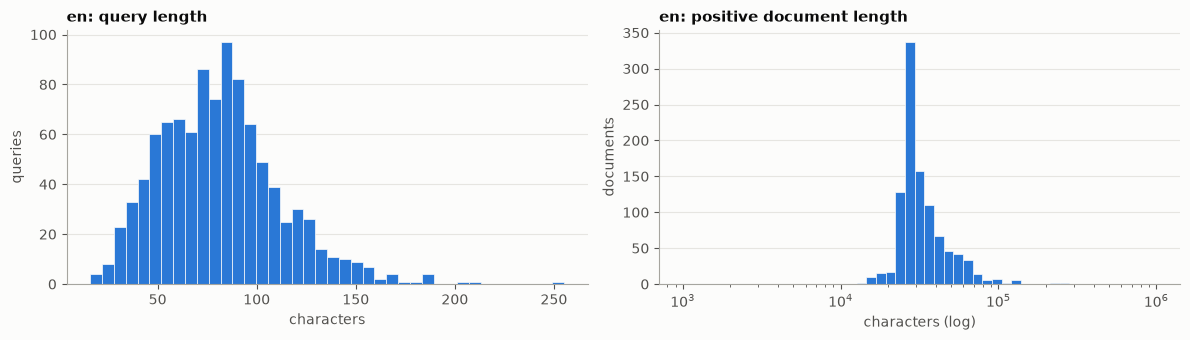

In [17]:
qs = q["query_chars"].describe(percentiles=[.1, .5, .9]).round(0)
ds = q["doc_chars"].describe(percentiles=[.1, .5, .9]).round(0)
display(pd.DataFrame({"query chars": qs, "positive doc chars": ds}))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(q["query_chars"], bins=40, color=ONE_SERIES, edgecolor=SURFACE, linewidth=0.5)
axes[0].set(title=f"{MAIN_LANG}: query length", xlabel="characters", ylabel="queries")
axes[1].hist(q["doc_chars"], bins=np.logspace(3, 6, 50), color=ONE_SERIES, edgecolor=SURFACE, linewidth=0.5)
axes[1].set(xscale="log", title=f"{MAIN_LANG}: positive document length", xlabel="characters (log)", ylabel="documents")
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()

### Look at an example

In [ ]:
def show(i: int = 0, split: str = SPLITS[0], doc_chars: int = 1200):
    r = raw[split][i]
    print(f"[{r['query_id']}] {r['query']}\n")
    for p in r["positive_passages"]:
        print(f"POSITIVE {p['docid']} ({len(p['text']):,} chars)")
        print(textwrap.fill(p["text"][:doc_chars], 110) + " ...\n")
    print("NEGATIVES (first 100 chars):")
    for p in r["negative_passages"]:
        print(f"  {p['docid']:>14} {len(p['text']):>8,} chars  {p['text'][:100]!r}")

show(0)

## What a clawmarc card can hold

The producer embeds the **full** extracted text in chunks of `CHUNK_TOKENS` tokens and averages the chunk vectors.
The card stores only about `CARD_TEXT_BYTES` of human-readable text, and that space also holds the title,
abstract, keywords and classification. Below: how many chunks each document needs, and what share of it fits in
the card's text area.

In [ ]:
qall["card_text_share"] = np.minimum(1.0, CARD_TEXT_BYTES / qall["doc_bytes"].clip(lower=1))
q["card_text_share"] = np.minimum(1.0, CARD_TEXT_BYTES / q["doc_bytes"].clip(lower=1))

if TOKENIZER:
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained(TOKENIZER)
    tok.model_max_length = 10**9  # we only count tokens; silences the >512 warning

    def chunk_stats(texts):
        n = np.array([len(ids) for ids in tok(list(texts), add_special_tokens=False)["input_ids"]])
        return n, np.maximum(1, np.ceil(n / CHUNK_TOKENS)).astype(int)

    # q holds the SPLITS of MAIN_LANG in load order, so the rows line up with raw
    q["doc_tokens"], q["chunks"] = chunk_stats(r["positive_passages"][0]["text"] for s in SPLITS for r in raw[s])
    display(q[["doc_tokens", "chunks", "card_text_share"]].describe(percentiles=[.1, .5, .9]).round(3))

    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.hist(q["chunks"], bins=range(1, q["chunks"].max() + 2), color=ONE_SERIES, edgecolor=SURFACE, linewidth=0.5)
    ax.set(title=f"{MAIN_LANG}: {CHUNK_TOKENS}-token chunks per positive doc ({TOKENIZER})",
           xlabel="chunks", ylabel="documents")
    ax.grid(axis="x", visible=False)
    plt.tight_layout()

qall.groupby("lang")["card_text_share"].describe(percentiles=[.5]).round(3)[["mean", "50%", "min", "max"]]

## Corpus of the main language (optional)

With `RUN_CORPUS = True` and `CORPUS_MAX_DOCS` set, the corpus is streamed from the Hub with
`load_dataset(..., streaming=True)` and only the lengths of the first `CORPUS_MAX_DOCS` documents are kept. With
`CORPUS_MAX_DOCS = None` the whole file is downloaded into the cache and read. (Putting the language in
`CORPUS_LANGS` loads the whole corpus too, for the overview charts.)

The English corpus file starts with the documents that the dev and test queries use, so reading only the
first few thousand lines does not give a random sample of the corpus.

In [ ]:
if RUN_CORPUS:
    judged = set(q["pos_docid"]) | {d for ids in q["neg_docids"] for d in ids}
    stream = load_corpus(MAIN_LANG, streaming=CORPUS_MAX_DOCS is not None)
    if CORPUS_MAX_DOCS is not None:
        stream = stream.take(CORPUS_MAX_DOCS)
    rows = [(d["docid"], len(d["text"]), len(d["text"].encode("utf-8")), d["docid"] in judged) for d in stream]
    corpus = pd.DataFrame(rows, columns=["docid", "chars", "bytes", "in_loaded_splits"])
    print(f"{len(corpus):,} corpus docs read; {corpus['in_loaded_splits'].sum():,} appear in the loaded splits")
    display(corpus[["chars", "bytes"]].describe(percentiles=[.1, .5, .9]).round(0))
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.hist(corpus["chars"], bins=np.logspace(2, 6, 60), color=ONE_SERIES, edgecolor=SURFACE, linewidth=0.5)
    ax.set(xscale="log", title=f"{MAIN_LANG}: corpus document length (first {len(corpus):,})",
           xlabel="characters (log)", ylabel="documents")
    ax.grid(axis="x", visible=False)
    plt.tight_layout()
else:
    print("RUN_CORPUS is False; skipped")

## Export documents for card minting (optional)

Writes `EXPORT_N` positive documents of `MAIN_LANG` as `.txt` files, together with a `queries.tsv` that maps each
query to its document. Each file can then be catalogued with:

```sh
python reference/libangel_catalog.py data/mldr/export/en/doc-en-0.txt \
  --schema reference/clawmarc_catalog_card.h \
  --content-policy reference/content_policies/public_library_science.json \
  --out-card cards_out/doc-en-0.cxcc --out-meta cards_out/doc-en-0.cxcc.json
```

In [ ]:
if EXPORT_N:
    out = DATA_DIR / "export" / MAIN_LANG
    out.mkdir(parents=True, exist_ok=True)
    lines = ["query_id\tdocid\tquery"]
    for r in [r for s in SPLITS for r in raw[s]][:EXPORT_N]:
        p = r["positive_passages"][0]
        (out / f"{p['docid']}.txt").write_text(p["text"], encoding="utf-8")
        lines.append(f"{r['query_id']}\t{p['docid']}\t{r['query']}")
    (out / "queries.tsv").write_text("\n".join(lines) + "\n", encoding="utf-8")
    print(f"wrote {EXPORT_N} documents and queries.tsv to {out}")
else:
    print("EXPORT_N is 0; skipped")